## Lab 12  
**Deep Neural Networks with Keras in TensorFlow: Task Framing, Binary Sentiment Classification, Multiclass Fault Diagnosis, and Regression for Bike Demand**


## Learning Objectives

By the end of this lab, you will be able to:

1. **Implement** multilayer perceptron (MLP) models in Keras for binary classification, multiclass classification, and regression.
2. **Validate** raw datasets with schema checks, label audits, missingness checks, and leakage-aware preprocessing.
3. **Compare** output activations and loss functions and **justify** why each pairing matches a specific supervised learning task.
4. **Evaluate** deep neural network models using task-appropriate metrics, visual diagnostics, and hold-out validation.
5. **Optimize** neural network training with regularization, early stopping, and threshold selection.
6. **Interpret** learning curves, confusion matrices, residual plots, and parameter counts.
7. **Debug** common modeling issues related to data shape, label encoding, overfitting, and unstable training.
8. **Monitor** system-level concerns including reproducibility, inference cost, drift risk, and performance regression.

## Tasks

- Set seeds, inspect library versions, and configure a reproducible TensorFlow/Keras environment.
- Frame supervised tasks correctly by matching output layers, activations, and losses.
- Download or load three real datasets and document their schemas, targets, and risks.
- Build a binary sentiment classifier for IMDb movie reviews using a dense bag-of-words MLP.
- Improve the binary classifier with regularization, early stopping, and threshold tuning.
- Build a multiclass classifier for Sensorless Drive Diagnosis using a dense tabular MLP.
- Diagnose multiclass errors with class-wise metrics and confusion matrices.
- Load the Bike Sharing hourly dataset and design a leakage-safe preprocessing pipeline.
- Train a linear regression baseline in Keras and compare it against a deeper nonlinear regressor.
- Analyze residuals and propose monitoring signals for production deployment.

**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## References

### Official Documentation

- [`tf.keras.Sequential`](https://keras.io/api/models/sequential/)
- [`tf.keras.layers.Dense`](https://keras.io/api/layers/core_layers/dense/)
- [`tf.keras.Model.compile`](https://keras.io/api/models/model_training_apis/)
- [`tf.keras.Model.fit`](https://keras.io/api/models/model_training_apis/)
- [`tf.keras.Model.evaluate`](https://keras.io/api/models/model_training_apis/)
- [`tf.keras.Model.predict`](https://keras.io/api/models/model_training_apis/)
- [`tf.keras.callbacks.EarlyStopping`](https://keras.io/api/callbacks/early_stopping/)
- [`tf.keras.datasets.imdb.load_data`](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/imdb/load_data)
- [`pandas.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
- [`sklearn.model_selection.train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
- [`sklearn.preprocessing.StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [`sklearn.compose.ColumnTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [`sklearn.preprocessing.OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [`sklearn.metrics.classification_report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
- [`sklearn.metrics.confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [`sklearn.metrics.mean_squared_error`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)

### References

- [Keras 3 API documentation](https://keras.io/api/)
- [TensorFlow IMDB dataset documentation](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/imdb/load_data)

### Python Commands / Quick Reference

- `tf.keras.Sequential([...])`
- `tf.keras.layers.Dense(units, activation=...)`
- `model.compile(optimizer=..., loss=..., metrics=[...])`
- `model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=..., batch_size=...)`
- `model.evaluate(X_test, y_test)`
- `model.predict(X_new)`
- `train_test_split(X, y, test_size=..., stratify=..., random_state=...)`
- `StandardScaler().fit(X_train)` then `.transform(...)`
- `ColumnTransformer([...]).fit(X_train)` then `.transform(...)`
- `classification_report(y_true, y_pred)`
- `confusion_matrix(y_true, y_pred)`

## Workflow Overview

1. Setup and reproducibility controls.
2. Frame neural network tasks by aligning output layers, activations, and losses.
3. Acquire and validate IMDb review data for binary classification.
4. Train and evaluate a binary baseline MLP.
5. Improve the binary classifier and diagnose threshold and error behavior.
6. Acquire and validate Sensorless Drive Diagnosis data for multiclass classification.
7. Train and evaluate a multiclass baseline MLP.
8. Improve the multiclass classifier and diagnose class confusions.
9. Acquire and preprocess Bike Sharing data with explicit leakage prevention.
10. Train and evaluate a linear regression baseline in Keras.
11. Train and evaluate an improved deep regressor and inspect residuals.
12. Summarize findings, monitoring plans, and deployment tradeoffs.

## Dataset

### A. Binary Classification — IMDb Large Movie Review Dataset
- **Dataset name:** Large Movie Review Dataset (IMDb)
- **Direct source:** https://ai.stanford.edu/~amaas/data/sentiment/
- **Programmatic loader used in this lab:** `tf.keras.datasets.imdb.load_data`
- **Description:** 25,000 labeled training reviews and 25,000 labeled test reviews for binary sentiment classification, with additional unlabeled raw data in the original release.
- **Features:** raw movie review text or integer-encoded word sequences
- **Target:** sentiment label (`0 = negative`, `1 = positive`)
- **Usage note:** cite Maas et al. (ACL 2011) when using the dataset academically.
- **Fallback option:** use `tf.keras.datasets.imdb` if the raw Stanford archive is unavailable.

### B. Multiclass Classification — Sensorless Drive Diagnosis
- **Dataset name:** UCI Dataset for Sensorless Drive Diagnosis
- **Direct source:** https://archive.ics.uci.edu/dataset/325/dataset+for+sensorless+drive+diagnosis
- **Programmatic loader used in this lab:** Direct download from UCI archive ZIP (the `ucimlrepo` API does not support this dataset)
- **Description:** numeric features extracted from motor current signals under multiple operating conditions and fault states.
- **Features:** 48 real-valued predictors
- **Target:** fault class with 11 mutually exclusive categories
- **Size:** 58,509 instances
- **License / usage note:** CC BY 4.0 on the UCI dataset page
- **Fallback option:** the raw `Sensorless_drive_diagnosis.txt` file linked from the UCI dataset page.

### C. Regression — Bike Sharing Dataset (hourly file)
- **Dataset name:** Bike Sharing
- **Direct source:** https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- **Direct archive link:** https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip
- **Description:** hourly bike rental counts with calendar and weather attributes from the Capital Bikeshare system (2011–2012).
- **Features:** weather, calendar, and time features from `hour.csv`
- **Regression target:** `cnt` (continuous total rentals)
- **Size:** 17,389 hourly observations
- **License / usage note:** CC BY 4.0 on the UCI dataset page
- **Fallback option:** `fetch_ucirepo(id=275)` or `day.csv` from the same archive if the hourly file is unavailable.

## Lab Instructions

| Step | Action |
|---|---|
| 1 | Configure imports, seeds, deterministic behavior, helper utilities, and environment reporting. |
| 2 | Match supervised task types to output activations, losses, metrics, and parameter counts. |
| 3 | Load IMDb data, inspect review lengths and label balance, and validate shapes and encoding. |
| 4 | Train a binary sentiment baseline MLP and interpret learning curves and confusion matrices. |
| 5 | Improve binary sentiment performance with regularization, early stopping, and threshold tuning. |
| 6 | Load Sensorless Drive Diagnosis data, validate class encoding, and build leakage-safe splits. |
| 7 | Train a multiclass baseline MLP and inspect class-wise performance. |
| 8 | Improve the multiclass model and analyze dominant confusions and reliability concerns. |
| 9 | Download the Bike Sharing hourly data, remove leakage columns, and preprocess mixed features safely. |
| 10 | Train a linear regression baseline in Keras and inspect error distributions. |
| 11 | Train a deeper regressor, compare results, and interpret residual patterns and deployment costs. |
| 12 | Report conclusions, limitations, and monitoring plans across all three tasks. |

### Step 1 — Setup & Reproducibility

### Pre-coding questions

1. What results are most likely to change when the random seed changes in a neural network experiment?
The initial weights, order of training batches, and any randomized operations can change when the seed changes. This can affect the learning curves, final accuracy, validation loss, and predictions.

2. Why might two machines still produce slightly different neural-network results even when the same seed is used?
Different hardware, TensorFlow versions, CUDA libraries, and numerical operations can produce slightly different results. Some GPU operations may also run in different orders, causing small floating-point differences even when the same seed is used.

3. Which experiment details should be logged before training starts?
I would log the random seed, Python and library versions, hardware information, dataset version, preprocessing settings, model architecture, optimizer, learning rate, batch size, and training parameters. This makes it easier to reproduce the experiment and understand differences between training runs.

### Function/class selection and parameter exploration

Use:

- `tf.keras.utils.set_random_seed`
- `tf.config.experimental.enable_op_determinism`
- `tf.keras.callbacks.EarlyStopping`
- `tf.keras.Sequential`

Explore with `help()` or notebook `?`:

- `tf.keras.utils.set_random_seed`
- `tf.keras.callbacks.EarlyStopping(monitor, patience, restore_best_weights, min_delta)`
- `tf.keras.layers.Dense(units, activation, input_shape)`

Explain the effect of:

- `seed` on reproducibility
- `patience` on training duration and overfitting risk
- `restore_best_weights` on evaluation validity
- `units` on model capacity, memory, and inference cost

In [1]:
# Step 1: Setup & reproducibility
import io
import os
import sys
import zipfile
import pathlib
import urllib.request
import warnings

# Configure TensorFlow behavior before importing tensorflow.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # suppress TF info/warning noise
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"         # avoid oneDNN non-determinism

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import gc

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception as exc:
    print("Determinism control not fully available:", exc)

plt.rcParams["figure.figsize"] = (8, 4)

def plot_history(history, metrics=None, title_prefix=""):
    metrics = metrics or ["loss"]
    history_df = pd.DataFrame(history.history)
    for metric in metrics:
        plt.figure()
        plt.plot(history_df.index + 1, history_df[metric], label=f"train_{metric}")
        val_metric = f"val_{metric}"
        if val_metric in history_df.columns:
            plt.plot(history_df.index + 1, history_df[val_metric], label=val_metric)
        plt.xlabel("Epoch")
        plt.ylabel(metric)
        plt.title(f"{title_prefix}{metric}")
        plt.legend()
        plt.tight_layout()
        plt.show()

def multi_hot_sequences(sequences, dimension):
    X = np.zeros((len(sequences), dimension), dtype=np.float32)
    for i, seq in enumerate(sequences):
        valid_tokens = [token for token in seq if token < dimension]
        X[i, valid_tokens] = 1.0
    return X

def root_mean_squared_error(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def make_one_hot_encoder():
    # Keep compatibility across sklearn versions.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python: 3.13.9
TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 2.3.3
GPU devices: []


**Think like an ML Systems engineer:**  
How would you make this notebook reproducible across machines, semesters, and retraining runs, not just within one interactive session?     
I would record the dataset version, random seeds, software versions, hardware configuration, preprocessing settings, and model parameters for every run. I would also save the trained model and preprocessing artifacts with a configuration file so the same experiment can be recreated later.

### Post-execution interpretation questions

1. Which printed environment details would you save with every trained model artifact?      
I would save the Python, TensorFlow, NumPy, and Pandas versions, along with the GPU information and random seed. I would also record the model architecture, training settings, and dataset version.

2. Why is `restore_best_weights=True` often preferable to using the final epoch weights when validation loss is monitored?      
The final epoch might have worse validation loss because the model started overfitting after reaching its best performance. Restoring the best weights keeps the version that performed best on the validation data.

3. What is the tradeoff between strict deterministic behavior and raw training speed?       
Deterministic operations make experiments easier to reproduce, but some operations may run more slowly. Disabling strict determinism can improve training speed, but results may vary slightly between runs.

### Step 2 — Task Framing and MLP Geometry

### Pre-coding questions

1. Why is `Dense(1, activation="sigmoid")` appropriate for one task type but inappropriate for another?     
A sigmoid output produces a value between 0 and 1, making it appropriate for binary classification because it can represent the probability of a positive class. It is not appropriate for standard regression because regression predictions need to represent a continuous range of values.

2. What would happen if you used a softmax output with mean squared error for a standard multiclass classifier?     
The model could still produce class probabilities, but mean squared error is not the standard loss for multiclass classification. Sparse categorical cross-entropy is generally a better choice because it directly measures the difference between the predicted class distribution and the correct class.

3. Why does adding more dense layers without nonlinear activations fail to increase expressive power?       
Without nonlinear activations, multiple dense layers can be combined into one linear transformation. Adding more layers would increase the number of parameters but would not allow the model to learn more complex nonlinear relationships.

### Function/class selection and parameter exploration

Use:

- `tf.keras.layers.Dense`
- `tf.keras.Sequential`
- `tf.keras.losses.BinaryCrossentropy`
- `tf.keras.losses.SparseCategoricalCrossentropy`
- `tf.keras.losses.MeanSquaredError`

Explore:

- `Dense(units, activation, use_bias)`
- `BinaryCrossentropy(from_logits=...)`
- `SparseCategoricalCrossentropy(from_logits=...)`
- `MeanSquaredError()`

Explain the effect of:

- `activation` on output interpretation
- `from_logits` on numerical stability and API correctness
- `units` on output dimensionality and parameter count
- `use_bias` on model flexibility and geometry of decision boundaries

In [2]:
# Step 2: Task framing table and parameter counting
task_frame = pd.DataFrame(
    [
        ["Regression", "Dense(1, activation='linear')", "MeanSquaredError()", "MAE, RMSE, R^2", "continuous target"],
        ["Binary classification", "Dense(1, activation='sigmoid')", "BinaryCrossentropy()", "accuracy, F1, AUC", "P(y=1|x)"],
        ["Multiclass classification", "Dense(K, activation='softmax')", "SparseCategoricalCrossentropy()", "accuracy, macro F1, confusion matrix", "class distribution"],
    ],
    columns=["Task", "Output layer", "Loss", "Typical metrics", "Output meaning"]
)

# Multilabel classification (e.g., multi-topic document tagging): independent sigmoid outputs
task_frame.loc[len(task_frame)] = [
    "Multilabel classification",
    "Dense(K, activation='sigmoid')",
    "BinaryCrossentropy()",
    "micro/macro F1",
    "independent label probabilities"
]

print(task_frame.to_string(index=False))

def dense_param_count(n_inputs, n_units, use_bias=True):
    return n_inputs * n_units + (n_units if use_bias else 0)

toy_model = keras.Sequential([
    layers.Input(shape=(20,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(11, activation="softmax")
])

toy_model.summary()
manual_total = dense_param_count(20, 32) + dense_param_count(32, 11)
print("Manual total parameters:", manual_total)

                     Task                   Output layer                            Loss                      Typical metrics                  Output meaning
               Regression  Dense(1, activation='linear')              MeanSquaredError()                       MAE, RMSE, R^2               continuous target
    Binary classification Dense(1, activation='sigmoid')            BinaryCrossentropy()                    accuracy, F1, AUC                        P(y=1|x)
Multiclass classification Dense(K, activation='softmax') SparseCategoricalCrossentropy() accuracy, macro F1, confusion matrix              class distribution
Multilabel classification Dense(K, activation='sigmoid')            BinaryCrossentropy()                       micro/macro F1 independent label probabilities


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 11)                  │             363 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,035 (4.04 KB)

 Trainable params: 1,035 (4.04 KB)

 Non-trainable params: 0 (0.00 B)

Manual total parameters: 1035


**Think like an ML Systems engineer:**  
Why is task framing a systems concern, not just a mathematical one? Consider monitoring, alerting, and the interpretation of predictions in downstream applications.        
Task framing determines what the model outputs mean and how other systems should use them. If the wrong activation or loss is selected, predictions could be interpreted incorrectly, causing problems with monitoring, alerting, or downstream decisions.

### Post-execution interpretation questions

1. Why does the manual parameter count match `model.summary()` for a dense network?         
Both calculations count the weights connecting the input neurons to the output neurons, along with the bias terms when they are enabled. The formula is the number of inputs multiplied by the number of units, plus the number of bias terms.

2. What failure mode appears if the output dimension does not match the label encoding?         
The model may produce predictions that do not correspond to the expected labels, or training may fail because the output and target shapes are incompatible. This can lead to incorrect classification results even if the code runs.

3. Which is riskier in production: using the wrong activation or the wrong loss? Justify briefly.           
Both can cause serious problems, but using the wrong activation can be especially dangerous because it changes how predictions are interpreted. For example, a system expecting probabilities could receive unrestricted raw scores and make incorrect decisions.

### Step 3 — Binary Classification Data Acquisition and Validation (IMDb)

### Pre-coding questions

1. What tradeoff do you make when you cap the vocabulary at the top `N` words?          
Capping the vocabulary reduces memory usage and makes the input representation smaller. However, less common words are removed, which could eliminate useful information that helps identify sentiment.

2. Why is it useful to inspect review lengths before choosing a representation?         
Review lengths help determine how much memory the data might require and whether long reviews need to be truncated. It also helps identify whether the chosen representation will work efficiently across reviews of different sizes.

3. Why can a perfectly balanced benchmark still be a poor proxy for production sentiment data?          
Real-world reviews may have a different distribution of positive and negative sentiment than the benchmark. Production data may also contain different vocabulary, writing styles, languages, and review lengths.

### Function/class selection and parameter exploration

Use:

- `tf.keras.datasets.imdb.load_data`
- `tf.keras.datasets.imdb.get_word_index`
- `sklearn.model_selection.train_test_split`

Explore:

- `imdb.load_data(num_words, skip_top, maxlen, seed, index_from)`
- `train_test_split(test_size, stratify, random_state)`

Explain the effect of:

- `num_words` on memory footprint and representational coverage
- `maxlen` on truncation and latency
- `skip_top` on removing extremely common words
- `stratify` on label balance and evaluation validity

In [3]:
# Step 3: Load IMDb data and validate structure
NUM_WORDS = 5000  # reduced from 10000 to lower memory footprint of multi-hot matrices

(imdb_train_seq, imdb_train_y_full), (imdb_test_seq, imdb_test_y) = keras.datasets.imdb.load_data(
    num_words=NUM_WORDS,
    seed=SEED
)

word_index = keras.datasets.imdb.get_word_index()
reverse_word_index = {index + 3: word for word, index in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<OOV>"
reverse_word_index[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(reverse_word_index.get(token, "?") for token in sequence)

# Structural validation: binary labels, vocabulary cap respected, decodable text
assert set(np.unique(imdb_train_y_full)).issubset({0, 1})
assert set(np.unique(imdb_test_y)).issubset({0, 1})

max_token = max(max(seq) for seq in imdb_train_seq if len(seq) > 0)
assert max_token < NUM_WORDS

sample_review = decode_review(imdb_train_seq[0])
assert isinstance(sample_review, str) and len(sample_review.strip()) > 0
print("Structural validation passed.")

X_train_binary, X_val_binary, y_train_binary, y_val_binary = train_test_split(
    imdb_train_seq,
    imdb_train_y_full,
    test_size=0.2,
    stratify=imdb_train_y_full,
    random_state=SEED
)

X_train_binary = multi_hot_sequences(X_train_binary, NUM_WORDS)
X_val_binary = multi_hot_sequences(X_val_binary, NUM_WORDS)
X_test_binary = multi_hot_sequences(imdb_test_seq, NUM_WORDS)

y_train_binary = np.asarray(y_train_binary, dtype=np.int32)
y_val_binary = np.asarray(y_val_binary, dtype=np.int32)
y_test_binary = np.asarray(imdb_test_y, dtype=np.int32)

print("Train shape:", X_train_binary.shape)
print("Validation shape:", X_val_binary.shape)
print("Test shape:", X_test_binary.shape)
print("Training label balance:", np.bincount(y_train_binary) / len(y_train_binary))
print("\nDecoded sample review snippet:")
print(decode_review(imdb_train_seq[0])[:500], "...")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Structural validation passed.
Train shape: (20000, 5000)
Validation shape: (5000, 5000)
Test shape: (25000, 5000)
Training label balance: [0.5 0.5]

Decoded sample review snippet:
<START> in panic in the streets richard widmark plays u s navy doctor who has his week <OOV> <OOV> with a corpse that contains plague as cop paul douglas properly points out the guy died from two bullets in the chest that's not the issue here the two of them become <OOV> <OOV> in an effort to find the killers and anyone else exposed to the disease br br as was pointed out by any number of people for some reason director <OOV> <OOV> did not bother to cast the small parts with anyone that sounds l ...


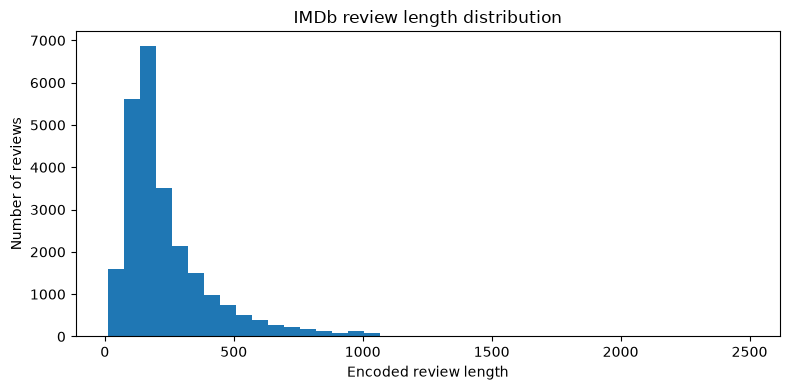

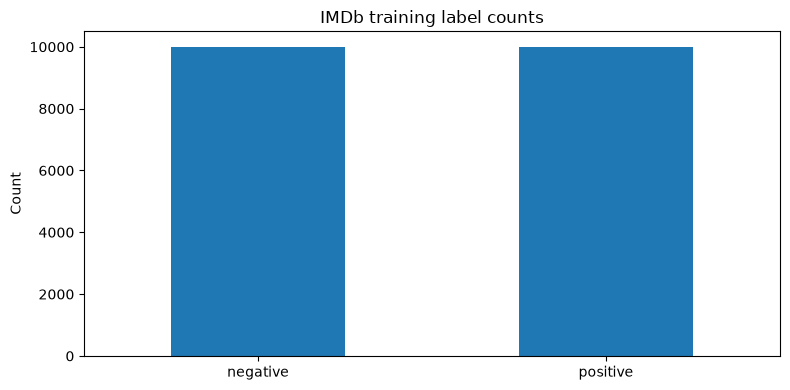

In [4]:
# Exploratory validation for review lengths and label balance
train_lengths = np.array([len(seq) for seq in imdb_train_seq])

plt.figure()
plt.hist(train_lengths, bins=40)
plt.xlabel("Encoded review length")
plt.ylabel("Number of reviews")
plt.title("IMDb review length distribution")
plt.tight_layout()
plt.show()

plt.figure()
pd.Series(y_train_binary).value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["negative", "positive"], rotation=0)
plt.ylabel("Count")
plt.title("IMDb training label counts")
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
If this model were deployed on live review streams, what would you log about incoming text so that vocabulary drift, length drift, and truncation problems can be detected early?           
I would monitor review lengths, the percentage of words outside the vocabulary, the frequency of unknown tokens, and the percentage of reviews being truncated. I would also track the distribution of predicted positive and negative sentiment to identify possible changes in incoming data.

### Post-execution interpretation questions

1. What do the review-length plots suggest about the memory cost of dense bag-of-words features?            
The review-length plots show how much the original review sizes vary, but the dense bag-of-words representation uses a fixed number of vocabulary features for every review. This means even short reviews require a full-length feature vector, which can increase memory usage.

2. Why might a dense MLP on multi-hot features still work well even though it ignores exact word order?         
Many words and combinations of words provide useful clues about whether a review is positive or negative. Even without word order, the model can learn patterns associated with sentiment from the presence of certain words.

3. What limitation does this representation impose compared with sequence models?           
It loses word order and the relationships between words in a sentence. As a result, it may struggle with negation, sarcasm, and phrases where the meaning depends on the order of the words.

### Step 4 — Binary Baseline MLP (IMDb)

### Pre-coding questions

1. Why is a sigmoid output with binary cross-entropy the standard baseline for this task?           
The task has two possible outcomes: positive or negative sentiment. Sigmoid produces a probability for the positive class, while binary cross-entropy measures how well that prediction matches the actual label.

2. What failure mode appears if the hidden layer is too small? What failure mode appears if it is too large?            
A hidden layer that is too small may underfit because it cannot learn enough patterns from the reviews. A layer that is too large may overfit the training data, increasing memory usage and inference cost.

3. Why is validation loss usually more informative than training accuracy for early stopping?           
Training accuracy only measures performance on data the model has already seen. Validation loss provides a better indication of how well the model generalizes to unseen data and can reveal overfitting earlier.

### Function/class selection and parameter exploration

Use:

- `tf.keras.Sequential`
- `tf.keras.layers.Dense`
- `tf.keras.optimizers.Adam`
- `tf.keras.callbacks.EarlyStopping`

Explore:

- `Dense(units, activation)`
- `Adam(learning_rate=...)`
- `EarlyStopping(monitor, patience, restore_best_weights)`

Explain the effect of:

- `learning_rate` on convergence stability
- `batch_size` on throughput and gradient noise
- `epochs` on overfitting risk
- hidden `units` on capacity and inference cost

Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7844 - auc: 0.8699 - loss: 0.5314 - val_accuracy: 0.8562 - val_auc: 0.9325 - val_loss: 0.3884
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8866 - auc: 0.9536 - loss: 0.3204 - val_accuracy: 0.8806 - val_auc: 0.9489 - val_loss: 0.3112
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9076 - auc: 0.9672 - loss: 0.2581 - val_accuracy: 0.8890 - val_auc: 0.9528 - val_loss: 0.2864
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9197 - auc: 0.9739 - loss: 0.2258 - val_accuracy: 0.8902 - val_auc: 0.9541 - val_loss: 0.2770
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9270 - auc: 0.9783 - loss: 0.2042 - val_accuracy: 0.8924 - val_auc: 0.9543 - val_loss: 0.2752
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9324 - auc: 0.9814 - loss: 0.1881 - val_accuracy: 0.8906 - val_auc: 0.9538 - val_loss: 0.2771
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step -

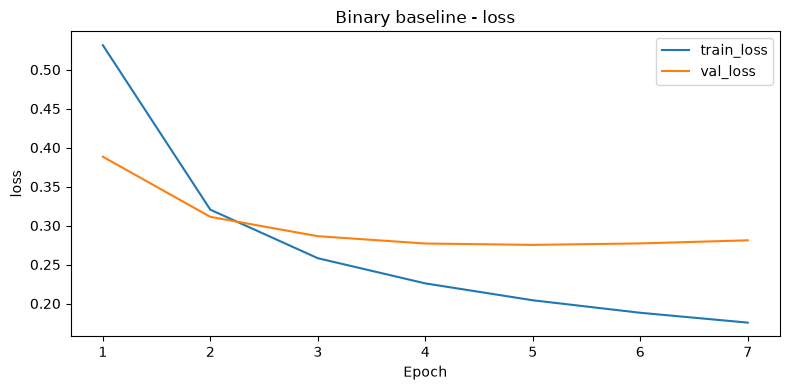

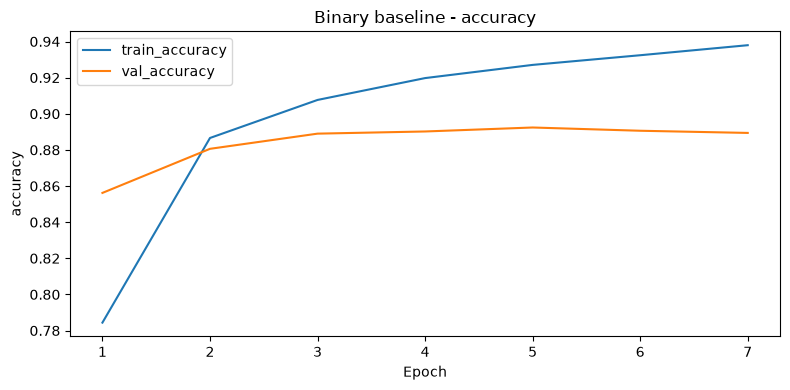

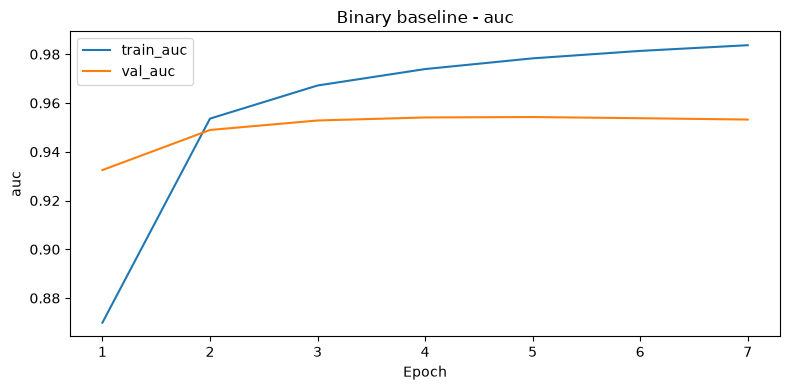

Reference baseline (16 units) best val loss: 0.2752
Variant baseline (32 units) best val loss : 0.2763
              precision    recall  f1-score   support

           0     0.8786    0.8852    0.8819     12500
           1     0.8843    0.8777    0.8810     12500

    accuracy                         0.8814     25000
   macro avg     0.8815    0.8814    0.8814     25000
weighted avg     0.8815    0.8814    0.8814     25000

Test AUC: 0.9480246656
Test F1 : 0.8809925319200193


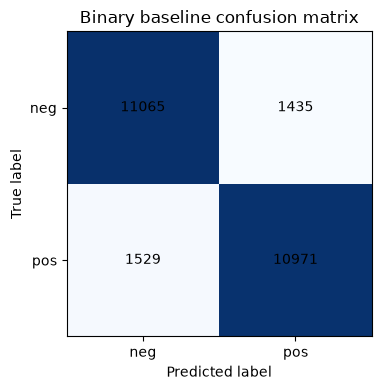

In [5]:
# Step 4: Baseline binary classifier
binary_baseline = keras.Sequential([
    layers.Input(shape=(NUM_WORDS,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

binary_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

binary_es = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_binary_baseline = binary_baseline.fit(
    X_train_binary,
    y_train_binary,
    validation_data=(X_val_binary, y_val_binary),
    epochs=40,
    batch_size=512,
    callbacks=[binary_es],
    verbose=1
)

plot_history(history_binary_baseline, metrics=["loss", "accuracy", "auc"], title_prefix="Binary baseline - ")

# Alternative baseline with 32 hidden units, same loss/optimizer, compared on validation loss
binary_baseline_variant = keras.Sequential([
    layers.Input(shape=(NUM_WORDS,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

binary_baseline_variant.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

history_binary_variant = binary_baseline_variant.fit(
    X_train_binary,
    y_train_binary,
    validation_data=(X_val_binary, y_val_binary),
    epochs=40,
    batch_size=512,
    callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=0
)

ref_val_loss = min(history_binary_baseline.history["val_loss"])
var_val_loss = min(history_binary_variant.history["val_loss"])
print(f"Reference baseline (16 units) best val loss: {ref_val_loss:.4f}")
print(f"Variant baseline (32 units) best val loss : {var_val_loss:.4f}")

binary_baseline_test_probs = binary_baseline.predict(X_test_binary, verbose=0).ravel()
binary_baseline_test_pred = (binary_baseline_test_probs >= 0.5).astype(int)

print(classification_report(y_test_binary, binary_baseline_test_pred, digits=4))

binary_baseline_cm = confusion_matrix(y_test_binary, binary_baseline_test_pred)
print("Test AUC:", roc_auc_score(y_test_binary, binary_baseline_test_probs))
print("Test F1 :", f1_score(y_test_binary, binary_baseline_test_pred))

plt.figure()
plt.imshow(binary_baseline_cm, cmap="Blues")
plt.title("Binary baseline confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], ["neg", "pos"])
plt.yticks([0, 1], ["neg", "pos"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, binary_baseline_cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
Where could leakage occur in this text pipeline? Consider vectorization, threshold choice, and any preprocessing that might use test data statistics.           
Leakage could occur if vocabulary selection, preprocessing, or threshold tuning uses information from the test data. The validation set should be used for model selection and threshold decisions, while the test set should only be used for final evaluation.

### Post-execution interpretation questions

1. What evidence would indicate underfitting in the baseline learning curves?           
Underfitting would be suggested if both training and validation performance remain poor. If both losses stay relatively high and accuracy does not improve much, the model may not have enough capacity to learn the patterns in the data.

2. Why can AUC remain high even when the default threshold yields unsatisfactory F1?            
AUC measures how well the model ranks positive examples above negative examples across different thresholds. F1 depends on the specific threshold used to convert probabilities into class predictions, so a threshold of 0.5 may not provide the best precision and recall balance.

3. Which metric would you prioritize if false positives are much more costly than false negatives?          
I would prioritize precision because it measures how many predicted positive examples are actually positive. Higher precision helps reduce false positive predictions.

### Step 5 — Binary Improvement and Diagnostics (IMDb)

### Pre-coding questions

1. Why might dropout help on high-dimensional sparse text features?         
Dropout randomly disables some neurons during training, which prevents the model from relying too heavily on specific features or connections. This can reduce overfitting when working with a large vocabulary and sparse text data.

2. Why should a decision threshold be chosen on validation data rather than on test data?               
The validation set is intended for tuning model decisions, including the classification threshold. Using the test set to select a threshold would introduce information from the test data into the modeling process and make the final evaluation less reliable.

3. What tradeoff do you make when scanning many thresholds?         
Testing more thresholds can help identify a better balance between precision and recall, but it also increases the chance of overfitting to the validation set. It also adds time to the model-selection process.

### Function/class selection and parameter exploration

Use:

- `tf.keras.layers.Dropout`
- `tf.keras.callbacks.EarlyStopping`
- `sklearn.metrics.f1_score`

Explore:

- `Dropout(rate)`
- `EarlyStopping(patience, restore_best_weights)`
- `f1_score(average=...)`

Explain the effect of:

- `rate` on regularization strength and optimization difficulty
- `patience` on training time
- threshold choice on precision/recall balance
- model width on quality versus latency

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7801 - auc: 0.8656 - loss: 0.4851 - val_accuracy: 0.8776 - val_auc: 0.9463 - val_loss: 0.3057
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8988 - auc: 0.9593 - loss: 0.2631 - val_accuracy: 0.8912 - val_auc: 0.9544 - val_loss: 0.2742
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9221 - auc: 0.9750 - loss: 0.2046 - val_accuracy: 0.8904 - val_auc: 0.9548 - val_loss: 0.2806
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9363 - auc: 0.9830 - loss: 0.1688 - val_accuracy: 0.8862 - val_auc: 0.9535 - val_loss: 0.3015
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9520 - auc: 0.9890 - loss: 0.1357 - val_accuracy: 0.8722 - val_auc: 0.9488 - val_loss: 0.3839


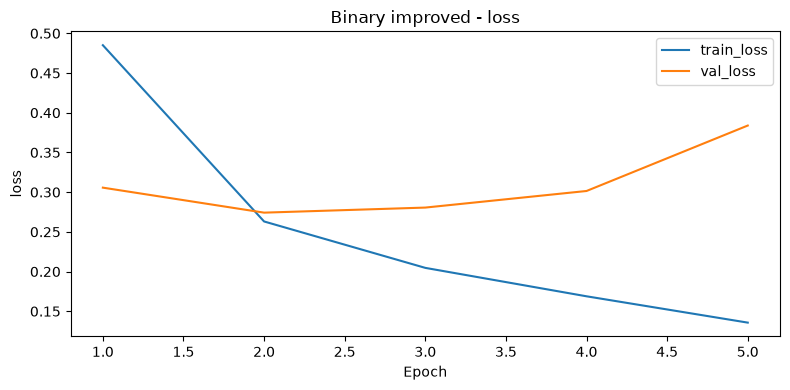

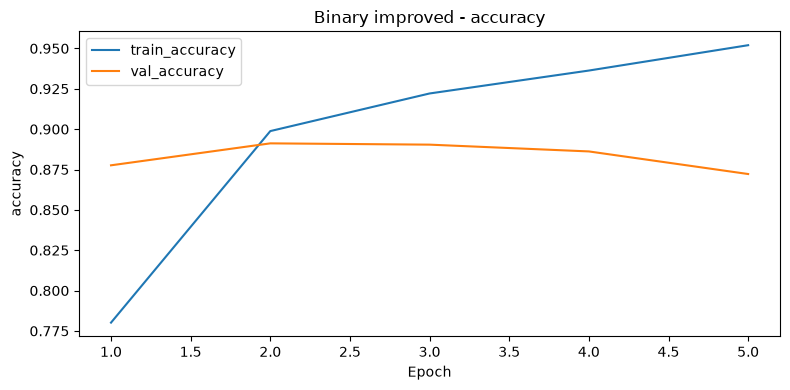

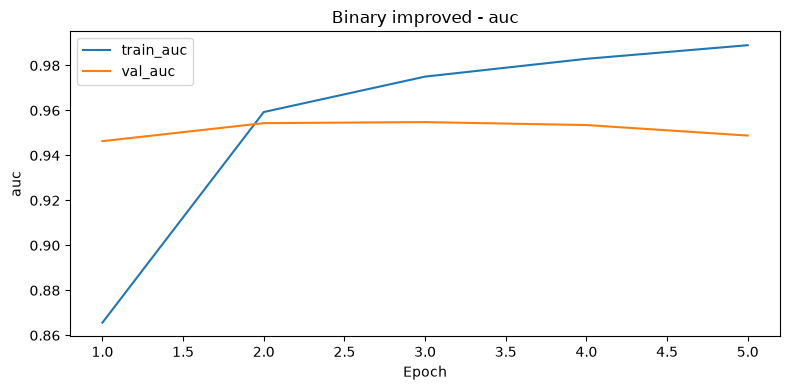

   threshold    val_f1
0       0.30  0.882605
1       0.35  0.887082
2       0.40  0.888590
3       0.45  0.892398
4       0.50  0.892533
5       0.55  0.891335
6       0.60  0.886497
7       0.65  0.882559
8       0.70  0.875759


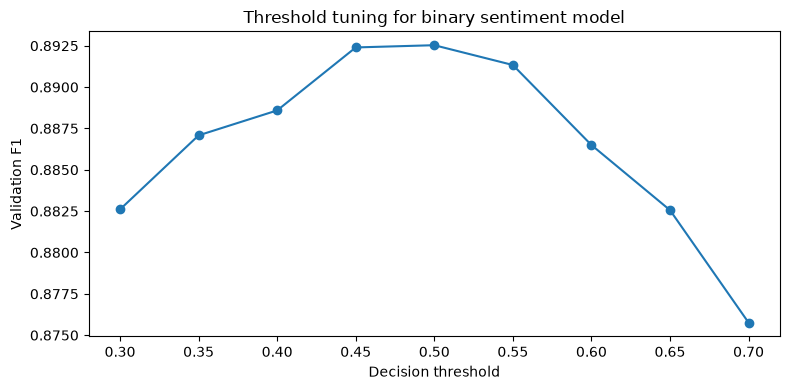

Chosen threshold: 0.49999999999999994
Improved test AUC: 0.9498786751999999
Improved test F1 : 0.8841408128671108
              precision    recall  f1-score   support

           0     0.8940    0.8678    0.8807     12500
           1     0.8715    0.8971    0.8841     12500

    accuracy                         0.8824     25000
   macro avg     0.8828    0.8824    0.8824     25000
weighted avg     0.8828    0.8824    0.8824     25000



In [6]:
# Step 5: Improved binary model with dropout and threshold tuning
binary_improved = keras.Sequential([
    layers.Input(shape=(NUM_WORDS,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

binary_improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

history_binary_improved = binary_improved.fit(
    X_train_binary,
    y_train_binary,
    validation_data=(X_val_binary, y_val_binary),
    epochs=15,
    batch_size=512,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=1
)

plot_history(history_binary_improved, metrics=["loss", "accuracy", "auc"], title_prefix="Binary improved - ")

val_probs = binary_improved.predict(X_val_binary, verbose=0).ravel()
threshold_grid = np.arange(0.30, 0.71, 0.05)
threshold_results = []

# Search the threshold grid and keep the threshold with the best validation F1
best_threshold = 0.50
best_f1 = -1.0

for threshold in threshold_grid:
    f1 = f1_score(y_val_binary, (val_probs >= threshold).astype(int))
    threshold_results.append((threshold, f1))
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

threshold_results = pd.DataFrame(threshold_results, columns=["threshold", "val_f1"])
print(threshold_results)

plt.figure()
plt.plot(threshold_results["threshold"], threshold_results["val_f1"], marker="o")
plt.xlabel("Decision threshold")
plt.ylabel("Validation F1")
plt.title("Threshold tuning for binary sentiment model")
plt.tight_layout()
plt.show()

test_probs = binary_improved.predict(X_test_binary, verbose=0).ravel()
test_pred = (test_probs >= best_threshold).astype(int)

print("Chosen threshold:", best_threshold)
print("Improved test AUC:", roc_auc_score(y_test_binary, test_probs))
print("Improved test F1 :", f1_score(y_test_binary, test_pred))
print(classification_report(y_test_binary, test_pred, digits=4))

In [7]:
# Error analysis: inspect highly confident mistakes
binary_errors = pd.DataFrame({
    "true_label": y_test_binary,
    "pred_prob": test_probs,
    "pred_label": test_pred
})
binary_errors["confidence"] = np.where(binary_errors["pred_label"] == 1, binary_errors["pred_prob"], 1 - binary_errors["pred_prob"])
binary_errors["is_error"] = binary_errors["true_label"] != binary_errors["pred_label"]

hard_errors = binary_errors[binary_errors["is_error"]].sort_values("confidence", ascending=False).head(5)
print(hard_errors)

if len(hard_errors) > 0:
    print("\nMost confident error example:")
    example_index = hard_errors.index[0]
    print(decode_review(imdb_test_seq[example_index])[:700], "...")

       true_label  pred_prob  pred_label  confidence  is_error
3861            0   0.999756           1    0.999756      True
17187           1   0.000314           0    0.999686      True
16685           1   0.000354           0    0.999646      True
21922           1   0.000572           0    0.999428      True
20127           1   0.000893           0    0.999107      True

Most confident error example:
<START> mickey <OOV> <OOV> diane lane in <OOV> <OOV> <OOV> it is not like mickey <OOV> ever really disappeared he has had a <OOV> string of appearances before he <OOV> back on the scene he was memorable in <OOV> sin city man on fire once upon a time in mexico and get carter but in his powerful dramatic performance in the <OOV> <OOV> we see a full blown presentation of the character only <OOV> at in get carter whenever we get to know him <OOV> remains a cool but sleazy <OOV> bound <OOV> ball br br this is an <OOV> leonard story and production leonard wrote such notable movies as <OOV> 

**Think like an ML Systems engineer:**  
What is the inference-time cost of a 10,000-dimensional dense input compared with a smaller vocabulary or a hashing-based representation? Which option would you deploy first under a strict latency budget?            
A 10,000-dimensional dense input requires more memory and computation than a smaller input representation. I would start with a smaller vocabulary under a strict latency budget because it is straightforward to implement and reduces the number of input features. A hashing-based representation could also be tested if vocabulary management becomes a problem.

### Post-execution interpretation questions

1. If validation F1 peaks at a threshold different from `0.5`, what does that tell you?             
It suggests that 0.5 is not the best decision threshold for this model and dataset. The model may produce probabilities that need a different cutoff to achieve a better balance between precision and recall.

2. Why are highly confident mistakes especially important during error analysis?            
Highly confident mistakes show cases where the model is strongly convinced but still predicts the wrong result. These examples can reveal weaknesses in the training data, vocabulary representation, or patterns the model has not learned correctly.

3. What should be monitored after deployment besides aggregate accuracy?            
I would monitor precision, recall, F1, AUC, prediction confidence, and the distribution of positive and negative predictions. I would also track vocabulary drift, review length changes, unknown words, and inference latency.

### Step 6 — Multiclass Data Acquisition and Validation (Sensorless Drive Diagnosis)

### Pre-coding questions

1. Why must class labels be checked before using `SparseCategoricalCrossentropy`?           
Sparse categorical cross-entropy expects class labels to be integer values representing the available output classes. Checking the labels ensures they are valid, properly encoded, and compatible with the model's output layer.

2. Why should scaling be fit on the training split only?            
Fitting the scaler on the entire dataset would allow information from the validation and test sets to influence preprocessing. Fitting it only on the training data prevents this leakage and ensures future data is transformed using the same training statistics.

3. Why might class-wise metrics matter even when overall accuracy is strong?            
Overall accuracy can hide poor performance on individual fault classes. Class-wise metrics help identify whether the model consistently misses certain fault types, which could be important in an industrial setting.

### Function/class selection and parameter exploration

Use:

- `urllib.request.urlretrieve` / `zipfile.ZipFile` (download from UCI archive)
- `pd.read_csv` (space-separated `.txt`, no header)
- `sklearn.model_selection.train_test_split`
- `sklearn.preprocessing.StandardScaler`

Explore:

- `pd.read_csv(path, sep=r"\s+", header=None)`
- `train_test_split(stratify=..., test_size=..., random_state=...)`
- `StandardScaler(with_mean, with_std)`

Explain the effect of:

- `stratify` on class preservation
- `with_mean` and `with_std` on numerical conditioning
- label indexing on compatibility with sparse categorical loss
- hidden width on parameter count and memory cost

In [8]:
# Step 6: Load Sensorless Drive Diagnosis data

# Free memory from IMDb multi-hot matrices before loading new data
for _v in ['X_train_binary', 'X_val_binary', 'X_test_binary']:
    if _v in globals():
        del globals()[_v]
gc.collect()
keras.backend.clear_session()

# UCI archive URL for the raw dataset (space-separated .txt inside a .zip)
uci_zip_url = "https://archive.ics.uci.edu/static/public/325/dataset+for+sensorless+drive+diagnosis.zip"
txt_path = "Sensorless_drive_diagnosis.txt"

if not os.path.exists(txt_path):
    print("Downloading Sensorless Drive Diagnosis data from UCI...")
    local_zip, _ = urllib.request.urlretrieve(uci_zip_url)
    with zipfile.ZipFile(local_zip, "r") as zf:
        txt_name = [n for n in zf.namelist() if n.endswith(".txt")][0]
        with open(txt_path, "wb") as f:
            f.write(zf.read(txt_name))
    print("Download complete.")

print("Loading data from", txt_path, "...")
# Raw file: 49 space-separated columns, no header.  Columns 1-48 = features, column 49 = class label.
raw_df = pd.read_csv(txt_path, sep=r"\s+", header=None)
X_sensorless = raw_df.iloc[:, :-1]
y_sensorless = raw_df.iloc[:, -1]

# Ensure y is an integer pd.Series (raw labels are 1-based: 1..11)
y_sensorless = pd.Series(y_sensorless).astype(int)

# Confirm that class labels are contiguous after zero-indexing, and print per-class counts.
y_sensorless_zero = y_sensorless - y_sensorless.min()

expected_classes = np.arange(y_sensorless_zero.nunique())
actual_classes = np.sort(y_sensorless_zero.unique())
assert np.array_equal(actual_classes, expected_classes), f"Noncontiguous labels: {actual_classes}"

print("Per-class counts:\n", y_sensorless_zero.value_counts().sort_index())

X_train_mc, X_temp_mc, y_train_mc, y_temp_mc = train_test_split(
    X_sensorless,
    y_sensorless_zero,
    test_size=0.30,
    stratify=y_sensorless_zero,
    random_state=SEED
)

X_val_mc, X_test_mc, y_val_mc, y_test_mc = train_test_split(
    X_temp_mc,
    y_temp_mc,
    test_size=0.50,
    stratify=y_temp_mc,
    random_state=SEED
)

sensorless_scaler = StandardScaler()
X_train_mc_scaled = sensorless_scaler.fit_transform(X_train_mc)
X_val_mc_scaled = sensorless_scaler.transform(X_val_mc)
X_test_mc_scaled = sensorless_scaler.transform(X_test_mc)

num_classes = int(y_sensorless_zero.nunique())

print("Training shape:", X_train_mc_scaled.shape)
print("Validation shape:", X_val_mc_scaled.shape)
print("Test shape:", X_test_mc_scaled.shape)
print("Number of classes:", num_classes)
print("Label range:", int(y_sensorless_zero.min()), "to", int(y_sensorless_zero.max()))


Download complete.
Loading data from Sensorless_drive_diagnosis.txt ...
Per-class counts:
 48
0     5319
1     5319
2     5319
3     5319
4     5319
5     5319
6     5319
7     5319
8     5319
9     5319
10    5319
Name: count, dtype: int64
Training shape: (40956, 48)
Validation shape: (8776, 48)
Test shape: (8777, 48)
Number of classes: 11
Label range: 0 to 10


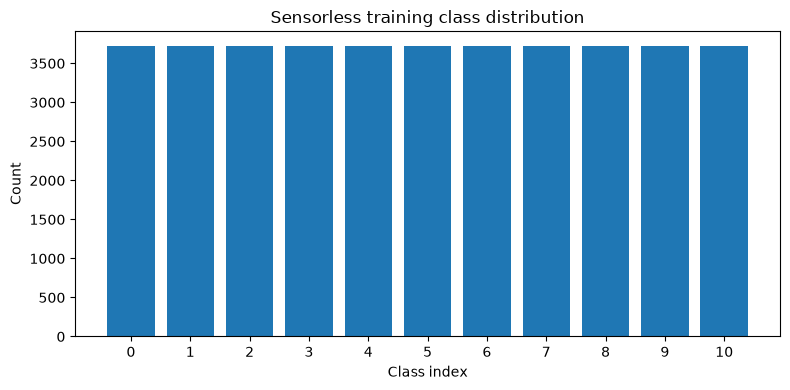

In [9]:
# Class-balance visualization
class_counts = y_train_mc.value_counts().sort_index()

plt.figure()
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Class index")
plt.ylabel("Count")
plt.title("Sensorless training class distribution")
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
What additional metadata would you want from the data-collection system to understand whether future failures come from new operating conditions, sensor drift, or class imbalance?             
I would want timestamps, sensor identifiers, machine identifiers, operating conditions, maintenance history, and the original fault labels. I would also track sensor ranges and summary statistics over time to identify changes in sensor behavior or new operating conditions.

### Post-execution interpretation questions

1. Why does tabular fault-diagnosis data usually benefit from scaling before dense neural networks?         
Different sensor measurements can have very different numerical ranges. Scaling makes the features more comparable, which can help the neural network train more consistently and prevent larger-valued features from dominating the optimization process.

2. What does a nearly balanced class distribution simplify, and what does it not eliminate?         
A nearly balanced distribution makes it easier to compare overall accuracy and class-wise performance because no single class dominates the dataset. However, it does not eliminate the need to examine precision, recall, confusion matrices, or differences in the difficulty of identifying individual fault classes.

3. Which preprocessing artifact must be saved with the trained model for future inference?          
The fitted StandardScaler must be saved with the model. Future sensor measurements need to be transformed using the same training means and standard deviations before being passed into the network.

### Step 7 — Multiclass Baseline MLP (Sensorless)

### Pre-coding questions

1. Why is softmax appropriate at the output layer here?         
The task involves 11 mutually exclusive fault classes. Softmax produces a probability distribution across the classes, allowing the model to select the class with the highest predicted probability.

2. Why is `SparseCategoricalCrossentropy` convenient for integer labels?            
It allows the model to use integer class labels directly instead of requiring one-hot encoded target labels. This makes the dataset easier to prepare and reduces unnecessary preprocessing.

3. What training symptom would suggest the network is too shallow or too narrow?            
The model may underfit, showing poor training and validation performance even after several epochs. If both losses remain high and accuracy stays low, the network may not have enough capacity to learn the relationships in the data.

### Function/class selection and parameter exploration

Use:

- `tf.keras.Sequential`
- `tf.keras.layers.Dense`
- `tf.keras.losses.SparseCategoricalCrossentropy`

Explore:

- `Dense(units, activation)`
- `SparseCategoricalCrossentropy()`
- `SparseCategoricalAccuracy()`

Explain the effect of:

- output `units=num_classes`
- hidden-layer width on parameter count
- `batch_size` on training speed and generalization
- `learning_rate` on stability

Epoch 1/3
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4394 - loss: 1.7140 - val_accuracy: 0.6387 - val_loss: 1.1982
Epoch 2/3
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7281 - loss: 0.9432 - val_accuracy: 0.7944 - val_loss: 0.7309
Epoch 3/3
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8298 - loss: 0.6126 - val_accuracy: 0.8638 - val_loss: 0.5110


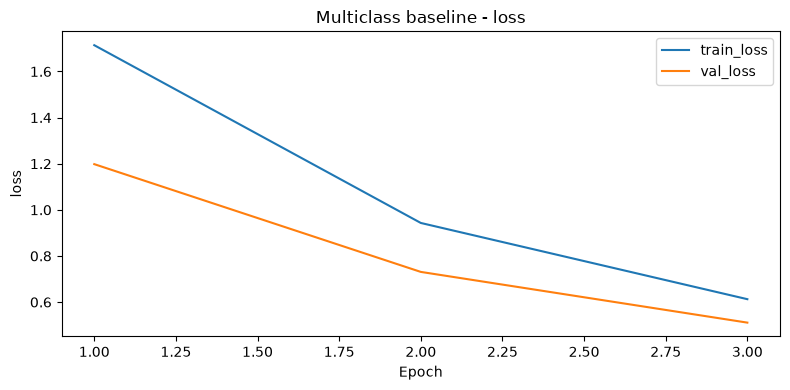

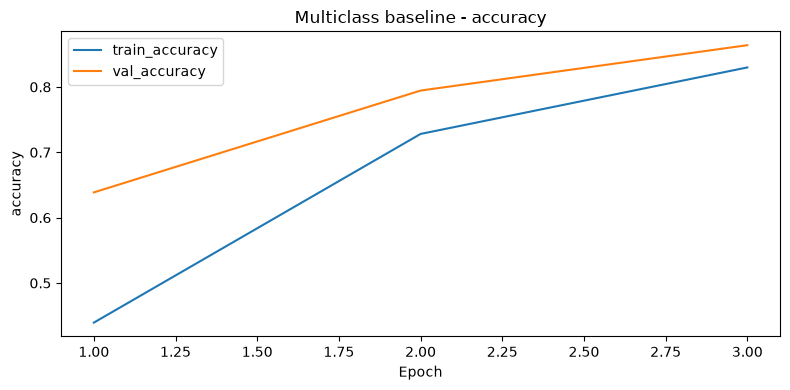

              precision    recall  f1-score   support

           0     0.7669    0.9536    0.8501       797
           1     0.7903    0.7318    0.7599       798
           2     0.9145    0.9386    0.9264       798
           3     0.9071    0.9173    0.9121       798
           4     0.9069    0.7206    0.8031       798
           5     0.7705    0.6015    0.6756       798
           6     0.9731    0.9987    0.9858       798
           7     0.8344    0.9536    0.8901       798
           8     0.8806    0.8596    0.8700       798
           9     0.7579    0.8120    0.7840       798
          10     0.9987    1.0000    0.9994       798

    accuracy                         0.8625      8777
   macro avg     0.8637    0.8625    0.8597      8777
weighted avg     0.8637    0.8625    0.8597      8777



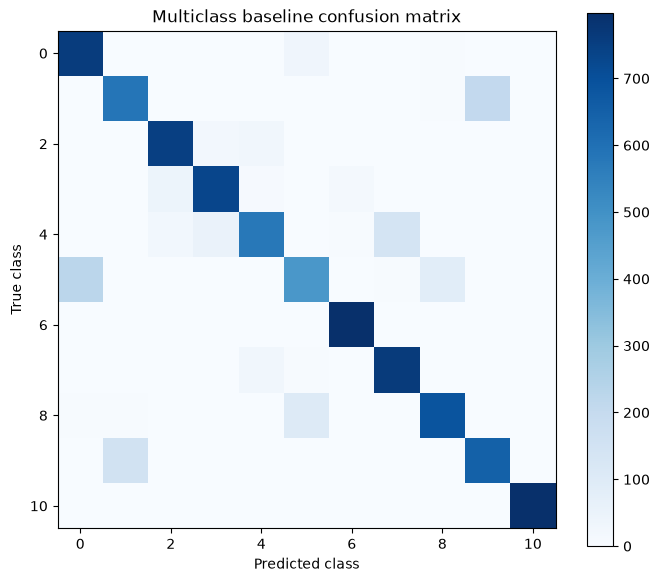

In [10]:
# Step 7: Baseline multiclass classifier
multiclass_baseline = keras.Sequential([
    layers.Input(shape=(X_train_mc_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

multiclass_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

history_multiclass_baseline = multiclass_baseline.fit(
    X_train_mc_scaled,
    y_train_mc,
    validation_data=(X_val_mc_scaled, y_val_mc),
    epochs=3,
    batch_size=256,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=1
)

plot_history(history_multiclass_baseline, metrics=["loss", "accuracy"], title_prefix="Multiclass baseline - ")

mc_baseline_probs = multiclass_baseline.predict(X_test_mc_scaled, verbose=0)
mc_baseline_pred = mc_baseline_probs.argmax(axis=1)

print(classification_report(y_test_mc, mc_baseline_pred, digits=4))

mc_baseline_cm = confusion_matrix(y_test_mc, mc_baseline_pred)

plt.figure(figsize=(7, 6))
plt.imshow(mc_baseline_cm, cmap="Blues")
plt.title("Multiclass baseline confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.colorbar()
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
Would you deploy the highest-accuracy model automatically for industrial fault diagnosis, or would you also require class-specific recall guarantees and calibrated confidence? Explain your operational stance.            
I would not deploy a model based only on its overall accuracy. I would also require acceptable recall for each important fault class and confidence estimates that are reliable enough to support maintenance decisions. Missing a serious fault could be more costly than making an incorrect prediction that triggers an additional inspection.

### Post-execution interpretation questions

1. Which classes appear easiest or hardest, and how can you tell?           
The easiest classes would have the highest recall and the strongest values along the diagonal of the confusion matrix. The hardest classes would have lower recall and more incorrect predictions in their corresponding rows. The actual class numbers should be identified from the notebook's classification report and confusion matrix.

2. Why can macro-level metrics be more informative than overall accuracy in fault diagnosis?        
Macro-level metrics give each class equal weight instead of allowing more common classes to dominate the result. This makes it easier to identify weaknesses in less common fault categories.

3. What limitation remains even if the confusion matrix looks strong on a held-out test split?          
The test data may not represent future operating conditions or sensor behavior. The model could still perform poorly when deployed on new machines, different environments, or data that has drifted from the training distribution.

### Step 8 — Multiclass Improvement and Diagnostics (Sensorless)

### Pre-coding questions

1. Why might a deeper network with dropout improve this task?           
A deeper network can learn more complex relationships between the sensor features and fault classes. Dropout can help prevent overfitting by reducing the model's dependence on specific neurons during training.

2. What does it mean operationally if two fault classes are consistently confused?          
It means the model has difficulty distinguishing between those two types of faults. In a real maintenance system, this could lead to incorrect repairs, delayed maintenance, or additional inspections.

3. Why might class confusion matter more than absolute accuracy in maintenance systems?         
Different fault types can have different levels of severity and require different maintenance actions. Confusing two serious fault classes could have a greater operational impact than a small decrease in overall accuracy.

### Function/class selection and parameter exploration

Use:

- `tf.keras.layers.Dropout`
- `tf.keras.callbacks.EarlyStopping`
- `sklearn.metrics.confusion_matrix`

Explore:

- `Dropout(rate)`
- `confusion_matrix(normalize=...)` in the scikit-learn docs
- `EarlyStopping(patience, restore_best_weights)`

Explain the effect of:

- `Dropout(rate)` on generalization
- `patience` on computation cost
- confusion-matrix normalization on interpretation
- deeper architecture on latency and memory

Epoch 1/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5283 - loss: 1.3686 - val_accuracy: 0.8149 - val_loss: 0.5937
Epoch 2/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8198 - loss: 0.5126 - val_accuracy: 0.9071 - val_loss: 0.3024
Epoch 3/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8774 - loss: 0.3454 - val_accuracy: 0.9335 - val_loss: 0.2196
Epoch 4/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9024 - loss: 0.2694 - val_accuracy: 0.9421 - val_loss: 0.1795
Epoch 5/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9199 - loss: 0.2274 - val_accuracy: 0.9557 - val_loss: 0.1523
Epoch 6/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9329 - loss: 0.1967 - val_accuracy: 0.9607 - val_loss: 0.1345
Epoch 7/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9411 - loss: 0.1757 - val_accuracy: 0.9659 - val_loss: 0.1203
Epoch 8/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9463 - loss: 0.1575 - val_accuracy: 0.

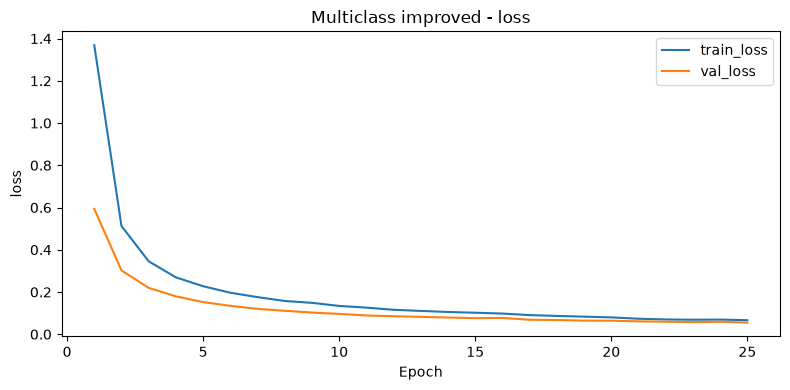

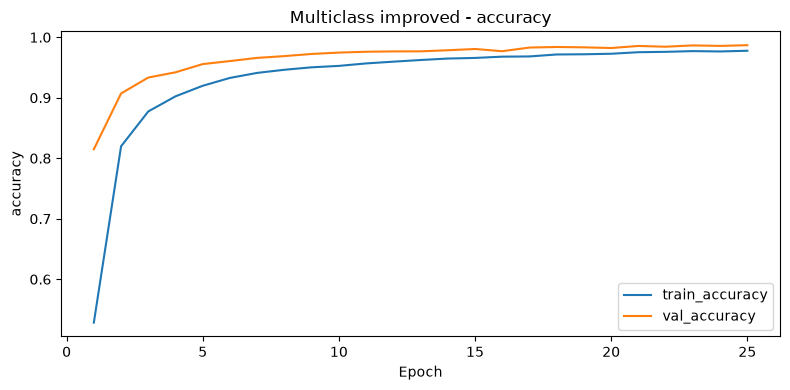

Improved model best val accuracy: 0.9869
Wider variant best val accuracy : 0.9905
Most confused pair: (1, 9) Count: 19
              precision    recall  f1-score   support

           0     0.9924    0.9849    0.9887       797
           1     0.9737    0.9737    0.9737       798
           2     0.9962    0.9975    0.9969       798
           3     0.9987    1.0000    0.9994       798
           4     0.9873    0.9762    0.9817       798
           5     0.9657    0.9887    0.9771       798
           6     1.0000    1.0000    1.0000       798
           7     0.9826    0.9887    0.9856       798
           8     0.9923    0.9749    0.9836       798
           9     0.9725    0.9762    0.9744       798
          10     1.0000    1.0000    1.0000       798

    accuracy                         0.9874      8777
   macro avg     0.9874    0.9874    0.9874      8777
weighted avg     0.9874    0.9874    0.9874      8777



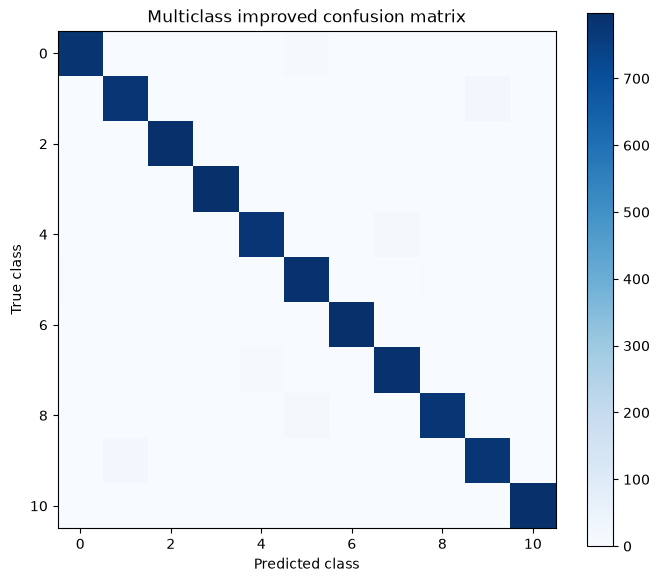

In [11]:
# Step 8: Improved multiclass model and confusion analysis
multiclass_improved = keras.Sequential([
    layers.Input(shape=(X_train_mc_scaled.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

multiclass_improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

history_multiclass_improved = multiclass_improved.fit(
    X_train_mc_scaled,
    y_train_mc,
    validation_data=(X_val_mc_scaled, y_val_mc),
    epochs=25,
    batch_size=256,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=1
)

plot_history(history_multiclass_improved, metrics=["loss", "accuracy"], title_prefix="Multiclass improved - ")

mc_improved_probs = multiclass_improved.predict(X_test_mc_scaled, verbose=0)
mc_improved_pred = mc_improved_probs.argmax(axis=1)

mc_improved_cm = confusion_matrix(y_test_mc, mc_improved_pred)
mc_off_diagonal = mc_improved_cm.copy()
np.fill_diagonal(mc_off_diagonal, 0)

# Wider multiclass variant with stronger dropout, compared on validation accuracy
multiclass_variant = keras.Sequential([
    layers.Input(shape=(X_train_mc_scaled.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(128, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

multiclass_variant.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

history_multiclass_variant = multiclass_variant.fit(
    X_train_mc_scaled,
    y_train_mc,
    validation_data=(X_val_mc_scaled, y_val_mc),
    epochs=25,
    batch_size=256,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=0
)

improved_val_acc = max(history_multiclass_improved.history["val_accuracy"])
variant_val_acc = max(history_multiclass_variant.history["val_accuracy"])
print(f"Improved model best val accuracy: {improved_val_acc:.4f}")
print(f"Wider variant best val accuracy : {variant_val_acc:.4f}")

# Find the most confused class pair (row, col) with the largest off-diagonal value
row_idx, col_idx = np.unravel_index(np.argmax(mc_off_diagonal), mc_off_diagonal.shape)
most_confused_pair = (int(row_idx), int(col_idx))

print("Most confused pair:", most_confused_pair, "Count:", mc_off_diagonal[row_idx, col_idx])
print(classification_report(y_test_mc, mc_improved_pred, digits=4))

plt.figure(figsize=(7, 6))
plt.imshow(mc_improved_cm, cmap="Blues")
plt.title("Multiclass improved confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.colorbar()
plt.tight_layout()
plt.show()

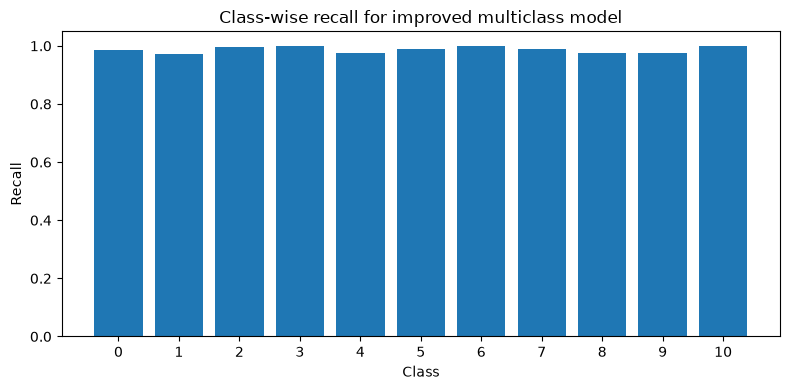

,class_id,recall,precision,f1
0,0,0.984944,0.992415,0.988665
1,1,0.973684,0.973684,0.973684
2,2,0.997494,0.996245,0.996869
3,3,1.000000,0.998748,0.999374
4,4,0.976190,0.987326,0.981727


In [12]:
# Class-wise recall visualization for the improved model
report_dict = classification_report(y_test_mc, mc_improved_pred, output_dict=True, zero_division=0)
class_rows = []
for class_name, metrics_dict in report_dict.items():
    if class_name.isdigit():
        class_rows.append((int(class_name), metrics_dict["recall"], metrics_dict["precision"], metrics_dict["f1-score"]))

class_metrics_df = pd.DataFrame(class_rows, columns=["class_id", "recall", "precision", "f1"]).sort_values("class_id")

plt.figure()
plt.bar(class_metrics_df["class_id"].astype(str), class_metrics_df["recall"])
plt.xlabel("Class")
plt.ylabel("Recall")
plt.title("Class-wise recall for improved multiclass model")
plt.tight_layout()
plt.show()

display(class_metrics_df.head())

**Think like an ML Systems engineer:**  
How would you detect a performance regression after deployment if ground-truth fault labels arrive late? What proxy signals could still warn you early?         
I would monitor prediction distributions, confidence scores, sensor measurements, and changes in operating conditions. I would also track the number of uncertain predictions and compare the frequency of predicted fault classes over time. Once actual fault labels become available, I would use them to calculate updated performance metrics.

### Post-execution interpretation questions

1. Why is the largest off-diagonal confusion often operationally more useful than the average metric?           
The largest off-diagonal value identifies the specific pair of classes that the model confuses most often. This gives a more direct indication of which mistakes could cause problems in a real maintenance system.

2. When would you prefer a slightly less accurate model with better class-wise stability?           
I would prefer it when the model provides more consistent performance across important fault categories. In industrial applications, reliably detecting every important fault type can be more valuable than achieving higher overall accuracy while performing poorly on certain classes.

3. What additional evidence would you want before trusting this model in a real industrial system?          
I would want to test the model on data from different machines and operating conditions, evaluate class-specific recall, and check prediction confidence. I would also want evidence that the model continues to perform reliably over time and does not fail when sensor measurements change.

### Step 9 — Regression Data Acquisition and Leakage (Bike Sharing)

### Pre-coding questions

1. Why is random shuffling dangerous for a time-indexed forecasting or demand-estimation dataset?           
Random shuffling can mix earlier and later observations between the training and testing sets. This can allow the model to learn from patterns that would not have been available at the time of prediction, making the evaluation less realistic.

2. Which columns in the raw bike-sharing file would create leakage if used to predict `cnt`?            
The casual and registered columns would create direct leakage because cnt is calculated by adding those two values together. The instant column is also removed in the lab, and dteday is excluded from the input features because the lab uses the other calendar and time attributes instead.

3. Why is a linear baseline still useful before fitting a deeper regressor?         
A linear baseline provides a simple reference point for evaluating whether a more complicated model is actually improving performance. It is also easier to understand, faster to train, and less expensive to deploy.

### Function/class selection and parameter exploration

Use:

- `tf.keras.utils.get_file`
- `pandas.read_csv`
- `sklearn.compose.ColumnTransformer`
- `sklearn.preprocessing.OneHotEncoder`
- `sklearn.preprocessing.StandardScaler`

Explore:

- `tf.keras.utils.get_file(origin, extract)`
- `ColumnTransformer(transformers=...)`
- `OneHotEncoder(handle_unknown, sparse_output)`
- `StandardScaler()`

Explain the effect of:

- chronological splitting on leakage prevention
- `handle_unknown="ignore"` on robustness to unseen categories
- one-hot encoding on feature dimensionality
- scaling on optimization quality

In [13]:
# Step 9: Load Bike Sharing hourly data and preprocess safely

# Free memory from Sensorless section
gc.collect()
keras.backend.clear_session()

bike_url = "https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip"
bike_zip_path = keras.utils.get_file(fname="bike_sharing_dataset.zip", origin=bike_url)

extract_dir = pathlib.Path(os.path.dirname(bike_zip_path)) / "bike_sharing_extracted"
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(bike_zip_path, "r") as zf:
    zf.extractall(extract_dir)

hour_candidates = list(extract_dir.rglob("hour.csv"))
if not hour_candidates:
    raise FileNotFoundError("hour.csv not found after extraction.")
hour_path = hour_candidates[0]

bike_df = pd.read_csv(hour_path)
bike_df["dteday"] = pd.to_datetime(bike_df["dteday"])
bike_df = bike_df.sort_values(["dteday", "hr"]).reset_index(drop=True)

# 'casual' and 'registered' are direct components of 'cnt' (cnt = casual + registered),
# so including them would leak the answer into the features and make evaluation meaningless.
target_col = "cnt"
drop_cols = ["instant", "dteday", "casual", "registered", "cnt"]

X_bike = bike_df.drop(columns=drop_cols)
y_bike = bike_df[target_col].astype(np.float32)

assert "casual" not in X_bike.columns
assert "registered" not in X_bike.columns

categorical_cols = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
numeric_cols = ["temp", "atemp", "hum", "windspeed"]

n_total = len(bike_df)
train_end = int(0.70 * n_total)
val_end = int(0.85 * n_total)

X_train_bike = X_bike.iloc[:train_end].copy()
X_val_bike = X_bike.iloc[train_end:val_end].copy()
X_test_bike = X_bike.iloc[val_end:].copy()

y_train_bike = y_bike.iloc[:train_end].copy()
y_val_bike = y_bike.iloc[train_end:val_end].copy()
y_test_bike = y_bike.iloc[val_end:].copy()

bike_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", make_one_hot_encoder(), categorical_cols),
    ]
)

X_train_bike_proc = bike_preprocessor.fit_transform(X_train_bike)
X_val_bike_proc = bike_preprocessor.transform(X_val_bike)
X_test_bike_proc = bike_preprocessor.transform(X_test_bike)

print("Train range:", bike_df.loc[:train_end - 1, "dteday"].min(), "to", bike_df.loc[:train_end - 1, "dteday"].max())
print("Validation range:", bike_df.loc[train_end:val_end - 1, "dteday"].min(), "to", bike_df.loc[train_end:val_end - 1, "dteday"].max())
print("Test range:", bike_df.loc[val_end:, "dteday"].min(), "to", bike_df.loc[val_end:, "dteday"].max())
print("Processed train shape:", X_train_bike_proc.shape)

 253952/Unknown 2s 6us/stepTrain range: 2011-01-01 00:00:00 to 2012-05-27 00:00:00
Validation range: 2012-05-27 00:00:00 to 2012-09-12 00:00:00
Test range: 2012-09-12 00:00:00 to 2012-12-31 00:00:00
Processed train shape: (12165, 61)


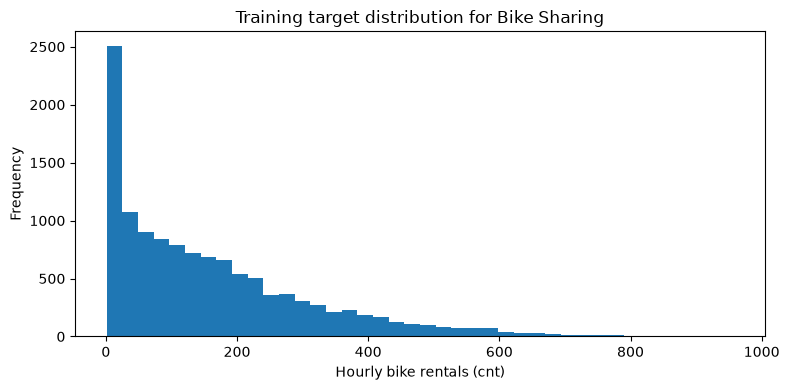

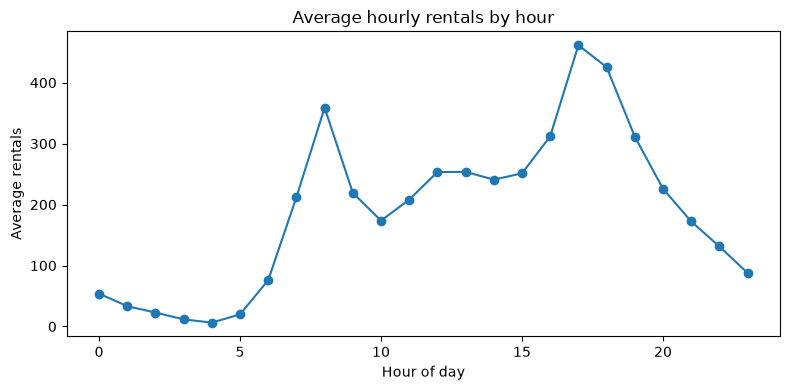

In [14]:
# Target behavior and seasonality inspection
plt.figure()
plt.hist(y_train_bike, bins=40)
plt.xlabel("Hourly bike rentals (cnt)")
plt.ylabel("Frequency")
plt.title("Training target distribution for Bike Sharing")
plt.tight_layout()
plt.show()

avg_by_hour = bike_df.groupby("hr")["cnt"].mean()
plt.figure()
plt.plot(avg_by_hour.index, avg_by_hour.values, marker="o")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.title("Average hourly rentals by hour")
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
Which future changes could break this regression model first: seasonal drift, holiday effects, weather-distribution shift, or feature-pipeline mismatch? Which would you monitor most closely?      
I would closely monitor feature-pipeline mismatches because missing or incorrectly transformed features could immediately affect every prediction. I would also monitor seasonal changes, holiday patterns, and weather distributions because they could change the relationship between the input features and bike demand.

### Post-execution interpretation questions

1. Why is chronological splitting more realistic than random splitting for this dataset?        
Bike demand changes over time due to weather, seasons, holidays, and other calendar effects. Chronological splitting tests whether the model can predict future demand using information from the past, which better represents a real deployment situation.

2. What does the hour-of-day curve suggest about the usefulness of nonlinear interactions?      
The average rental counts can vary significantly throughout the day rather than following a simple linear pattern. This suggests that nonlinear relationships and interactions between hour, working day, and other features could help improve predictions.

3. Why is `handle_unknown="ignore"` operationally safer than failing on unseen categories?          
It allows the model to continue processing data even when a new category appears. Without it, the preprocessing pipeline could fail and prevent predictions from being generated.

### Step 10 — Regression Baseline in Keras (Linear Output)

### Pre-coding questions

1. Why must the output layer be linear rather than sigmoid for this regression task?        
The target is the number of bike rentals, which is a continuous numerical value. A linear output allows the model to predict values across a wider range, while sigmoid restricts predictions to between 0 and 1.

2. Why is mean squared error a natural baseline loss for continuous targets?        
Mean squared error measures the average squared difference between predicted and actual values. It penalizes larger errors more heavily, making it a useful baseline loss for regression.

3. What would underfitting look like in the residual plot of a linear model?        
Underfitting could appear as a noticeable pattern in the residuals instead of random points around zero. For example, the model might consistently underpredict during busy hours and overpredict during quieter periods.

### Function/class selection and parameter exploration

Use:

- `tf.keras.layers.Dense`
- `tf.keras.losses.MeanSquaredError`
- `tf.keras.metrics.MeanAbsoluteError`
- `tf.keras.metrics.RootMeanSquaredError`

Explore:

- `Dense(1, activation="linear")`
- `MeanSquaredError()`
- `MeanAbsoluteError()`
- `RootMeanSquaredError()`

Explain the effect of:

- linear output on prediction range
- `batch_size` on regression training throughput
- `epochs` on underfitting versus overfitting
- baseline simplicity on interpretability and latency

Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 48163.2891 - mae: 157.9648 - rmse: 219.4614 - val_loss: 125826.3359 - val_mae: 275.9936 - val_rmse: 354.7201
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 46686.0195 - mae: 154.0461 - rmse: 216.0695 - val_loss: 122739.9219 - val_mae: 271.0185 - val_rmse: 350.3426
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 45264.3945 - mae: 150.5316 - rmse: 212.7543 - val_loss: 119745.3594 - val_mae: 266.4401 - val_rmse: 346.0424
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 43896.4414 - mae: 147.2772 - rmse: 209.5148 - val_loss: 116839.9766 - val_mae: 262.1551 - val_rmse: 341.8186
Epoch 5/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 42580.1289 - mae: 144.2022 - rmse: 206.3495 - val_loss: 114021.0781 - val_mae: 258.0561 - val_rmse: 337.6701
Epoch 6/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 41313.5898 - mae: 141.2816 - rmse: 203.2574 - val_loss: 111286.2031 - val_mae: 254.1004 - val_rmse: 333.595

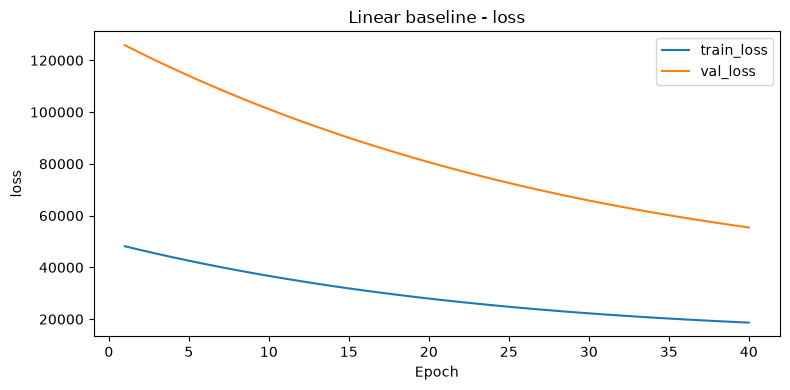

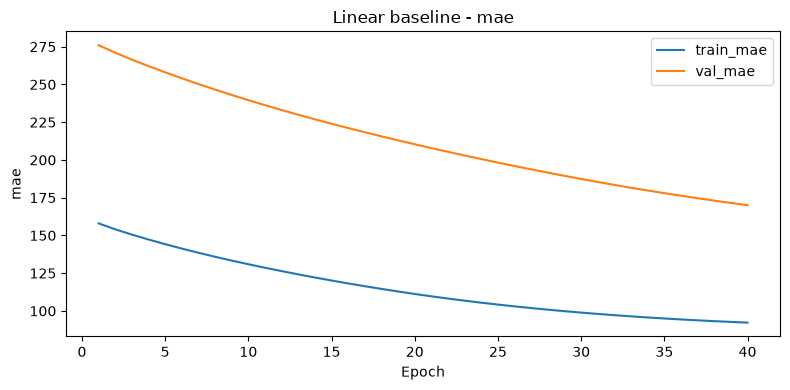

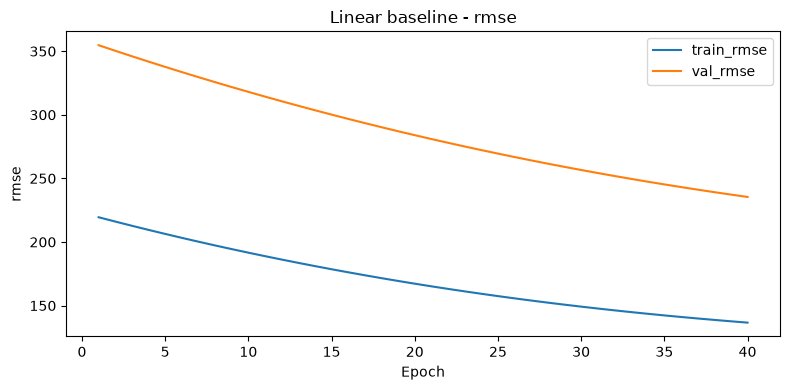

Linear baseline MAE : 155.85626220703125
Linear baseline RMSE: 228.71277019440782
Linear baseline R^2 : -0.13056433200836182


In [15]:
# Step 10: Linear regression baseline in Keras
linear_regressor = keras.Sequential([
    layers.Input(shape=(X_train_bike_proc.shape[1],)),
    layers.Dense(1, activation="linear")
])

linear_regressor.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-2),
    loss=keras.losses.MeanSquaredError(),
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

history_linear = linear_regressor.fit(
    X_train_bike_proc,
    y_train_bike,
    validation_data=(X_val_bike_proc, y_val_bike),
    epochs=40,
    batch_size=256,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=1
)

plot_history(history_linear, metrics=["loss", "mae", "rmse"], title_prefix="Linear baseline - ")

linear_pred = linear_regressor.predict(X_test_bike_proc, verbose=0).ravel()
linear_residuals = y_test_bike.to_numpy() - linear_pred

print("Linear baseline MAE :", mean_absolute_error(y_test_bike, linear_pred))
print("Linear baseline RMSE:", root_mean_squared_error(y_test_bike, linear_pred))
print("Linear baseline R^2 :", r2_score(y_test_bike, linear_pred))

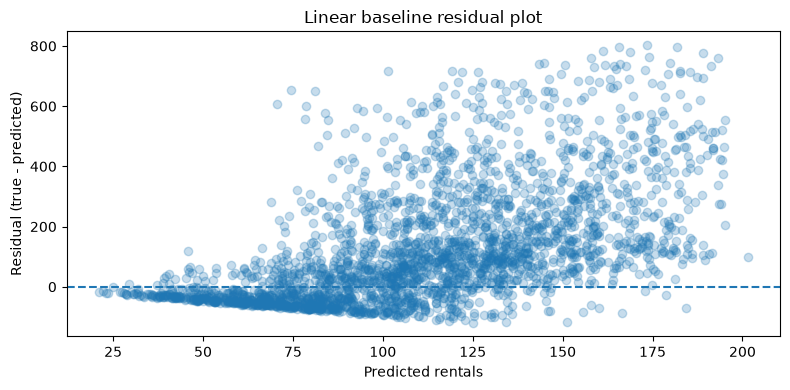

Hours with the largest mean underprediction (positive residual = underpredicted):
hr
17    432.627838
18    367.713470
8     362.901306
16    268.826660
19    223.633774
Name: residual, dtype: float32


In [16]:
# Residual diagnostics for the linear baseline
plt.figure()
plt.scatter(linear_pred, linear_residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted rentals")
plt.ylabel("Residual (true - predicted)")
plt.title("Linear baseline residual plot")
plt.tight_layout()
plt.show()

# Group residuals by hour to identify where the model underpredicts the most
residual_frame = X_test_bike.copy()
residual_frame["true_cnt"] = y_test_bike.to_numpy()
residual_frame["pred_cnt"] = linear_pred
residual_frame["residual"] = residual_frame["true_cnt"] - residual_frame["pred_cnt"]

hour_bias = residual_frame.groupby("hr")["residual"].mean().sort_values(ascending=False)
print("Hours with the largest mean underprediction (positive residual = underpredicted):")
print(hour_bias.head())

**Think like an ML Systems engineer:**  
Why might a simple linear model still be attractive in production, even if a deeper model is somewhat more accurate?        
A linear model is easier to maintain, interpret, and debug. It also requires fewer computational resources and generally has lower inference latency. If the deeper model only provides a small improvement, the simpler model may be a better choice for production.

### Post-execution interpretation questions

1. What evidence in the metrics or residuals would justify moving beyond the linear baseline?       
I would consider a deeper model if the linear model has relatively high MAE or RMSE and its residual plot shows clear patterns. Consistent errors during certain hours or demand levels would suggest that the model is not capturing important nonlinear relationships.

2. Why is RMSE often larger than MAE on this dataset?       
RMSE penalizes large errors more heavily because the errors are squared before being averaged. If the model makes a few large prediction errors, RMSE will increase more than MAE.

3. What operational risk appears if the model underpredicts rush-hour demand?       
Underpredicting rush-hour demand could cause a shortage of available bikes at busy locations. This could lead to customer dissatisfaction and make it harder for the bike-sharing system to meet demand.

### Step 11 — Improved Deep Regressor and Diagnostics (Bike Sharing)

### Pre-coding questions

1. Why might a deeper regressor outperform the linear baseline on this dataset?     
Bike demand depends on relationships between time, weather, seasons, and working days that may not be linear. A deeper network can learn more complicated patterns and interactions between these features.

2. What overfitting signal would you watch for in the learning curves?          
I would watch for training loss continuing to decrease while validation loss starts increasing. This would suggest that the model is learning the training data but becoming worse at generalizing to unseen observations.

3. Why is residual analysis still necessary after test-set metrics improve?         
Overall metrics do not show exactly where the model makes mistakes. Residual analysis can reveal patterns such as consistent underprediction during rush hours or larger errors at certain demand levels.

### Function/class selection and parameter exploration

Use:

- `tf.keras.layers.Dense`
- `tf.keras.layers.Dropout`
- `tf.keras.callbacks.EarlyStopping`

Explore:

- `Dense(units, activation)`
- `Dropout(rate)`
- `EarlyStopping(patience, restore_best_weights)`

Explain the effect of:

- hidden `units` on capacity and compute
- `Dropout(rate)` on regularization strength
- `patience` on optimization time
- deeper architecture on inference latency versus accuracy

Epoch 1/60
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 45919.7852 - mae: 152.1580 - rmse: 214.2890 - val_loss: 111176.9375 - val_mae: 254.0080 - val_rmse: 333.4321
Epoch 2/60
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 28543.6797 - mae: 115.4108 - rmse: 168.9487 - val_loss: 51167.6289 - val_mae: 166.1591 - val_rmse: 226.2026
Epoch 3/60
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15777.9404 - mae: 96.3345 - rmse: 125.6103 - val_loss: 38471.5039 - val_mae: 145.6944 - val_rmse: 196.1415
Epoch 4/60
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 13236.4746 - mae: 86.2294 - rmse: 115.0499 - val_loss: 33593.1367 - val_mae: 137.1217 - val_rmse: 183.2843
Epoch 5/60
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 11354.1113 - mae: 78.9075 - rmse: 106.5557 - val_loss: 29890.5742 - val_mae: 130.2233 - val_rmse: 172.8889
Epoch 6/60
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 9748.8594 - mae: 72.3721 - rmse: 98.7363 - val_loss: 26392.6387 - val_mae: 124.0386 - val_rmse: 162.4581
Epoch 7/6

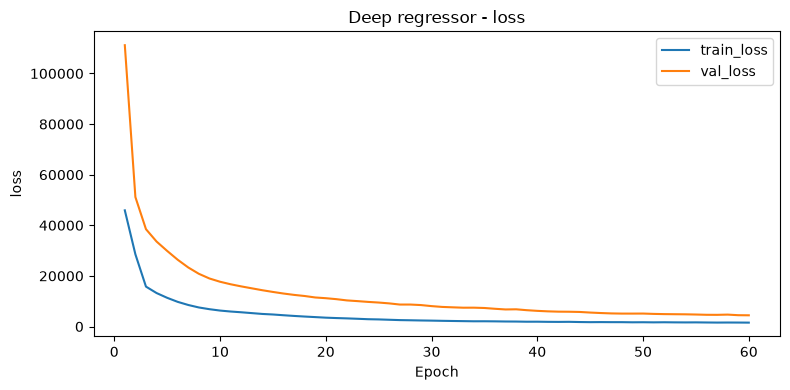

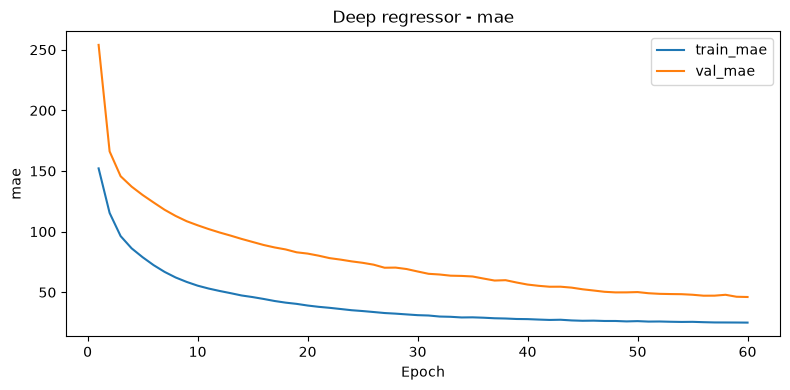

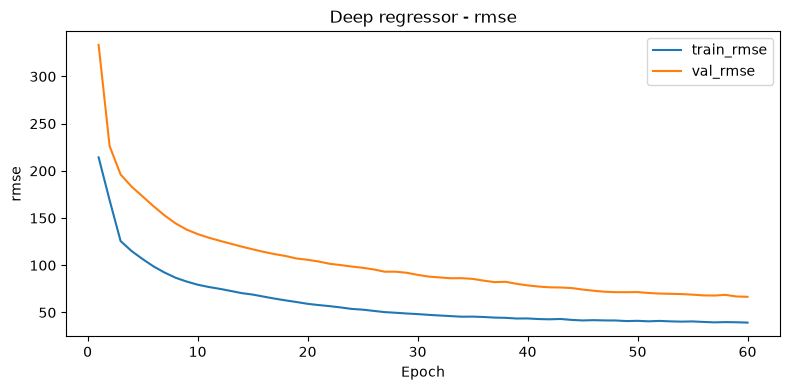

,model,mae,rmse,r2
0,linear_baseline,155.856262,228.712770,-0.130564
1,deep_regressor,58.103382,79.033536,0.864999


In [17]:
# Step 11: Improved nonlinear regressor
deep_regressor = keras.Sequential([
    layers.Input(shape=(X_train_bike_proc.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")
])

deep_regressor.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.MeanSquaredError(),
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

history_deep = deep_regressor.fit(
    X_train_bike_proc,
    y_train_bike,
    validation_data=(X_val_bike_proc, y_val_bike),
    epochs=60,
    batch_size=256,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=1
)

plot_history(history_deep, metrics=["loss", "mae", "rmse"], title_prefix="Deep regressor - ")

deep_pred = deep_regressor.predict(X_test_bike_proc, verbose=0).ravel()
deep_residuals = y_test_bike.to_numpy() - deep_pred

comparison = pd.DataFrame({
    "model": ["linear_baseline", "deep_regressor"],
    "mae": [
        mean_absolute_error(y_test_bike, linear_pred),
        mean_absolute_error(y_test_bike, deep_pred)
    ],
    "rmse": [
        root_mean_squared_error(y_test_bike, linear_pred),
        root_mean_squared_error(y_test_bike, deep_pred)
    ],
    "r2": [
        r2_score(y_test_bike, linear_pred),
        r2_score(y_test_bike, deep_pred)
    ]
})

display(comparison)

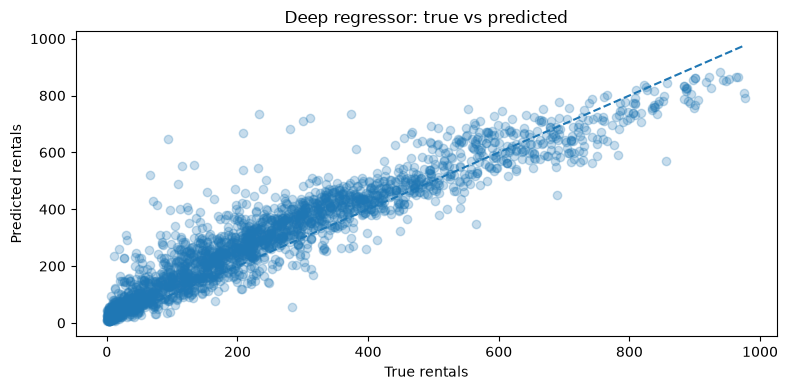

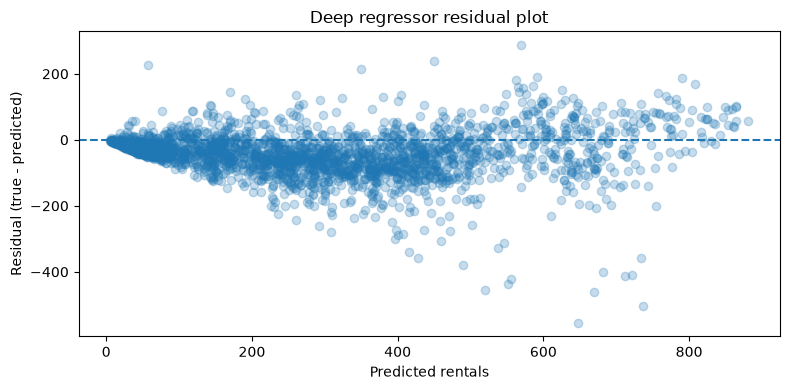

In [18]:
# Diagnostic plots for the improved regressor
plt.figure()
plt.scatter(y_test_bike, deep_pred, alpha=0.25)
min_val = min(float(y_test_bike.min()), float(deep_pred.min()))
max_val = max(float(y_test_bike.max()), float(deep_pred.max()))
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("True rentals")
plt.ylabel("Predicted rentals")
plt.title("Deep regressor: true vs predicted")
plt.tight_layout()
plt.show()

plt.figure()
plt.scatter(deep_pred, deep_residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted rentals")
plt.ylabel("Residual (true - predicted)")
plt.title("Deep regressor residual plot")
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
When would you still reject the deeper regressor for deployment even if it wins on RMSE? Consider serving cost, debugging difficulty, monitoring burden, and robustness to drift.           
I would reject the deeper regressor if its improvement in RMSE was too small to justify its additional cost and complexity. A simpler model may be easier to maintain and more reliable when the input data changes. I would also consider whether the deeper model requires more expensive hardware or makes production monitoring more difficult.

### Post-execution interpretation questions

1. If the deep regressor improves RMSE but not MAE very much, what does that suggest?           
It suggests that the deeper model may be reducing a smaller number of large prediction errors without greatly improving the typical prediction error. Since RMSE penalizes large errors more heavily than MAE, those improvements can have a noticeable effect on RMSE.

1. What residual pattern would suggest the model still struggles during peak hours?         
A pattern of consistently positive residuals during peak hours would indicate that the model is underpredicting demand. Since residuals are calculated as actual values minus predicted values, positive residuals mean actual demand was higher than the prediction.

1. Which signals would you monitor in production to detect regression drift?            
I would monitor MAE, RMSE, prediction distributions, residual patterns, and errors grouped by hour or season once actual demand values become available. I would also monitor changes in weather conditions, feature distributions, missing values, and preprocessing failures.

# Reflection

1. Across the three tasks, which output activation/loss pairing would you now consider the most intuitive, and why?             
I would consider sigmoid with binary cross-entropy the most intuitive pairing because the output directly represents the probability of a positive or negative sentiment classification. The loss function also directly measures how well that probability matches the correct label.

2. Where was leakage risk highest in this lab, and how was it controlled?           
The Bike Sharing task had a particularly clear leakage risk because the casual and registered columns directly add up to the target cnt. These columns were removed before training. The lab also used chronological splitting and fitted preprocessing only on the training data to prevent information from future observations from influencing the model.

3. Which model would you deploy first under a strict latency budget, and which would you keep only for offline analysis?            
I would start with the linear regression model for bike demand because it is simple, fast, and inexpensive to run. I would keep the deeper regressor for offline analysis and comparison until its accuracy improvement could be shown to justify its additional complexity and inference cost.

4. Which additional experiment would you run next for each task: regularization, calibration, feature engineering, thresholding, or a different architecture?           
IMDb sentiment classification: I would consider different threshold values to get a more accurate probability estimates and better balance between precision and recall.

Sensorless Drive diagnosis: I would consider using regularization and different architectures to improve generalisation and decrease confusion between different fault types.

Bike Sharing regression: I would focus on creating new features from the existing ones, particularly those based on time and interactions between hour, weather and working days.


**End of Lab**